# Autoregressive model

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mongo_wrangle import get_data
from statsmodels.graphics.tsaplots import plot_acf,plot_pacf
from time_series_preprocessing import make_data_stationary,reverse_stationary
from sklearn.metrics import mean_absolute_error,root_mean_squared_error
from statsmodels.tsa.ar_model import AutoReg

In [2]:
host="localhost"
port = 27017

In [3]:
# get data
df =get_data(port,host,"passengers","air_passengers")
df["month"]=pd.to_datetime(df["month"])
df=df.set_index("month")

In [4]:
df.head()

,total_passengers
month,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


In [5]:
# make data stationary
stat_df =make_data_stationary(df).dropna()

In [6]:
stat_df.head()

,total_passengers,log_passengers,log_diff,log_diff_seasonal
month,,,,
1950-02-01,126,4.836282,0.091350,0.039164
1950-03-01,141,4.948760,0.112478,0.000361
1950-04-01,135,4.905275,-0.043485,-0.020496
1950-05-01,125,4.828314,-0.076961,-0.012939
1950-06-01,149,5.003946,0.175633,0.066148


### Calculate and plot ACF

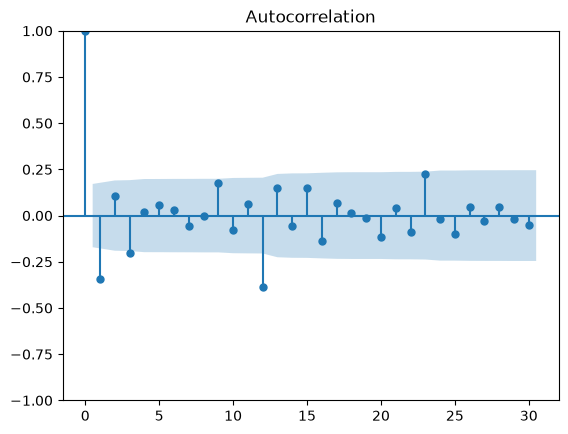

In [7]:
plot_acf(stat_df["log_diff_seasonal"],lags=30)
plt.show()

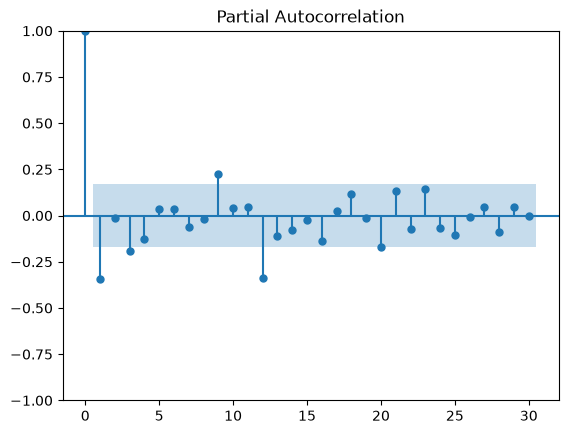

In [8]:
plot_pacf(stat_df["log_diff_seasonal"],lags=30,method="ywm")
plt.show()

Based on PACF graph only lag 1,3,9,12 and 20 are statistically significant . I choose lag 3 as ar orderbecause is last 
significant lag before the pattern cuts off(before the values consistently stay within the noise level.)

In [9]:
ar_order=3

### Split the data

In [10]:
split_idx=int(len(stat_df)*0.8)
split_idx

104

In [11]:
#original data
original_train_data=df.iloc[:split_idx]
original_test_data=df.iloc[split_idx:]

# stationary data
train_data =stat_df["log_diff_seasonal"][:split_idx]
test_data=stat_df["log_diff_seasonal"][split_idx:]

## Baseline

In [12]:
test_data.head()

month
1958-10-01    0.033998
1958-11-01   -0.017737
1958-12-01   -0.013289
1959-01-01    0.054187
1959-02-01    0.015601
Name: log_diff_seasonal, dtype: float64

In [13]:
# make prediction using last observation
y_pred_baseline=original_test_data.shift(1).dropna()
# align with shifted prediction
y_true_baseline=original_test_data[1:]

In [14]:
# calculate baseline mae
mean_absolute_error(y_true_baseline,y_pred_baseline)

10.667315841652048

Air passenger prediction is off by around 11 passengers

### Autoregressive model

In [15]:
# fit the model
model_ar=AutoReg(train_data,lags=3)
model_ar_fitted=model_ar.fit()

# print summary
model_ar_fitted.summary()

/opt/anaconda3/envs/air-env/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


<class 'statsmodels.iolib.summary.Summary'>
"""
                            AutoReg Model Results                             
==============================================================================
Dep. Variable:      log_diff_seasonal   No. Observations:                  101
Model:                     AutoReg(3)   Log Likelihood                 173.821
Method:               Conditional MLE   S.D. of innovations              0.043
Date:                Sat, 31 Oct 2026   AIC                           -337.641
Time:                        13:07:16   BIC                           -324.566
Sample:                    05-01-1950   HQIC                          -332.348
                         - 09-01-1958                                         
========================================================================================
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                   -0.0004      0.004     -0.095      0.924      -0.009       0.008
log_diff_seasonal.L1    -0.3304      0.098     -3.367      0.001      -0.523      -0.138
log_diff_seasonal.L2    -0.0801      0.103     -0.776      0.438      -0.282       0.122
log_diff_seasonal.L3    -0.2257      0.098     -2.301      0.021      -0.418      -0.033
                                    Roots                                    
=============================================================================
                  Real          Imaginary           Modulus         Frequency
-----------------------------------------------------------------------------
AR.1           -1.4508           -0.0000j            1.4508           -0.5000
AR.2            0.5480           -1.6593j            1.7475           -0.1992
AR.3            0.5480           +1.6593j            1.7475            0.1992
-----------------------------------------------------------------------------
"""

### Walk forward validation


In [16]:
train_data = train_data.asfreq("MS")
test_data = test_data.asfreq("MS")

In [17]:
predictions=[]
history =train_data.copy()


for t in range(len(test_data)):
    model=AutoReg(history,lags=ar_order)
    model_fitted=model.fit()
    
    # make one step ahead prediction
    y_pred=model_fitted.forecast(steps=1)
    predictions.append(y_pred.iloc[0])
    
    # add actual observation to history
    history=pd.concat([history,test_data.iloc[[t]]])
    
y_pred_ar=pd.Series(predictions,index=test_data.index)

In [18]:
y_pred_ar.head()

month
1958-10-01    0.018093
1958-11-01   -0.010785
1958-12-01    0.020478
1959-01-01   -0.002012
1959-02-01   -0.013846
Freq: MS, dtype: float64

In [23]:
# reverse stationary
pasenger_pred_test=reverse_stationary(y_pred_ar,df)

In [26]:
y_true_ar=original_test_data["total_passengers"].loc[pasenger_pred_test.index]

In [29]:
mae_ar=mean_absolute_error(y_true_ar,pasenger_pred_test)
mae_ar

50.301126229694184

ar model is off by 50 passengers

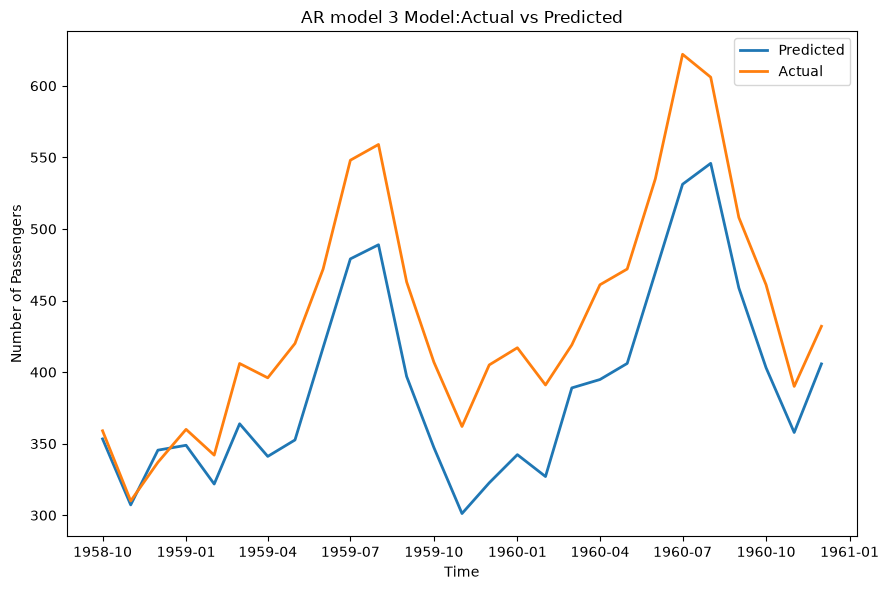

In [32]:
fig,ax=plt.subplots(figsize=(9,6))
ax.plot(y_true_ar.index,pasenger_pred_test,label="Predicted",linewidth=2)
ax.plot(y_true_ar.index,y_true_ar,label="Actual",linewidth=2)
ax.set_xlabel("Time")
ax.set_ylabel("Number of Passengers")
ax.set_title(f"AR model {ar_order} Model:Actual vs Predicted")
ax.legend()
plt.tight_layout()
plt.show()